<div align="center">

# Semantic Saturation Benchmark (SSB)
### Quand le contexte cesse d'aider : mesure contrôlée de la saturation sémantique des modèles NLP classiques

**Projet du module Traitement Automatique du Langage Naturel**
École Nationale Supérieure de l'Intelligence Artificielle et Sciences des Données – Taroudant
Enseignant du module : **Dr. Adil Baqach** · Année universitaire 2026 – 2027

</div>

## Membres du groupe et répartition des tâches

| Membre | Contribution principale |
|---|---|
| **Yassine Bouachrine** | Collecte et préparation des données : chargement d'AG News et de SQuAD 2.0, découpage en phrases, normalisation des paragraphes (108–132 tokens), constitution des réservoirs de remplissage aléatoire et des négatifs difficiles. |
| **Abdeljalil Nahimy** | Génération des perturbations : paraphrases par rétro-traduction MarianMT (en→fr→en), contradictions par remplacement d'entités nommées avec spaCy, contrôles de validité des échantillons. |
| **Mohamed Khacha** | Modèles et exécution : implémentation des trois tâches (classification, recherche, question-réponse), décodeur de QA à fenêtres glissantes, exécution complète sur GPU T4 (Kaggle). |
| **Abdelali Hirri** | Évaluation et analyse : métriques, intervalles de confiance bootstrap, correction de Holm, indicateurs de saturation (N*, N†, SSS), test des hypothèses, figures et rédaction. |

La conception du benchmark, la rédaction des hypothèses pré-enregistrées et l'interprétation des résultats ont été réalisées en commun.

Le code complet du projet est disponible dans le dépôt : <https://github.com/0khacha/semantic-saturation>. Ce notebook en présente la démarche, les données, la méthodologie et les résultats ; les cellules de code s'exécutent sur un simple processeur en quelques minutes, à partir du jeu de données et des prédictions versionnés dans le dépôt.

## Sommaire

1. Problématique
2. Mise en place de l'environnement
3. Les données
4. Méthodologie
5. Résultats
6. Discussion
7. Conclusion et perspectives

## 1. Problématique

Les systèmes de traitement automatique du langage reçoivent des entrées de plus en plus longues : documents entiers, résultats de recherche concaténés, historiques de conversation. Une hypothèse implicite guide souvent leur conception : fournir plus de texte ne peut qu'aider, puisque le modèle dispose alors de davantage d'informations.

Cette hypothèse est fragile. Un texte supplémentaire peut **diluer** l'information utile, introduire des passages **proches du sujet mais trompeurs**, contenir une affirmation **contradictoire**, ou repousser l'élément pertinent au-delà de ce que le modèle peut lire (la plupart des encodeurs BERT sont limités à 512 tokens). Les évaluations existantes confondent généralement ces mécanismes : Jia et Liang (2017) ajoutent une phrase distractrice, Liu et al. (2024) déplacent le passage utile, Shi et al. (2023) insèrent des phrases hors sujet, mais chacun ne fait varier qu'un facteur, sur une seule tâche.

Nous appelons **saturation sémantique** le point à partir duquel l'ajout de contexte cesse d'améliorer un modèle, puis commence à le rendre moins fiable. La question de recherche est la suivante :

> *À quel moment, et pour quelle raison, un contexte plus long cesse-t-il d'aider un modèle NLP classique, et comment cette dégradation se manifeste-t-elle sur la précision comme sur la fiabilité de ses prédictions ?*

Pour y répondre, nous avons construit un banc d'essai dans lequel le paragraphe qui contient l'information utile, le **signal**, reste strictement identique, tandis que son environnement varie selon cinq axes indépendants. Nous nous limitons volontairement à des modèles classiques (TF-IDF, BM25, encodeurs BERT de taille modeste), sans grand modèle de langage, afin d'expliquer les résultats par le fonctionnement connu de ces représentations et de garder l'expérience reproductible en moins d'une heure sur un GPU gratuit.

## 2. Mise en place de l'environnement

La cellule suivante se place à la racine du dépôt (et le clone si le notebook est ouvert ailleurs, par exemple sur Colab ou Kaggle), puis importe le paquet `ssb` qui contient tout le code du projet.

In [1]:
import os, sys, subprocess
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "ssb").exists():
    if (ROOT.parent / "ssb").exists():
        ROOT = ROOT.parent
    else:  # Colab / Kaggle : on récupère le dépôt
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/0khacha/semantic-saturation.git"], check=True)
        ROOT = ROOT / "semantic-saturation"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.3f}" if abs(x) < 1 else f"{x:.1f}")

from ssb.config import load_config
from ssb.build import load_dataset, load_paragraphs

cfg = load_config("configs/main.yaml")
print("Racine du dépôt :", ROOT)
print("Configuration   :", cfg.name, "| graine", cfg.seed)

Racine du dépôt : C:\projects\semantic-saturation
Configuration   : main | graine 20261119


Toute l'expérience est décrite par un seul fichier de configuration YAML, validé strictement au chargement (une clé inconnue ou une valeur invalide est rejetée). En voici le contenu :

In [2]:
print(Path("configs/main.yaml").read_text(encoding="utf-8"))

# Full v0.1: 300 base examples per task, every axis, every model.
name: main
seed: 20261119

data:
  path: data/ssb_v0.1.jsonl
  version: "0.1"
  raw_dir: data/raw
  tokenizer: bert-base-uncased        # every token count uses this WordPiece tokenizer
  paragraph_tokens: 120
  tolerance: 0.10                     # filler, paraphrases and swapped copies: 108-132 tokens
  examples: {classification: 300, retrieval: 300, qa: 300}
  qa_unanswerable_share: 0.5
  random_pool: 3000
  hard_pool: 4000
  selector_model: sentence-transformers/all-mpnet-base-v2   # not an evaluated model
  ner_model: en_core_web_sm
  paraphrase_models: [Helsinki-NLP/opus-mt-en-fr, Helsinki-NLP/opus-mt-fr-en]
  label_judge: fabriceyhc/bert-base-uncased-ag_news          # not an evaluated model
  device: auto

conditions:
  sizes: [1, 5, 20, 100]
  axes: [dilution, noise, redundancy, contradiction, position]
  base_filler: random
  redundancy_k: 5
  redundancy_modes: [copy, paraphrase]
  contradiction_positions: [bef

## 3. Les données

### 3.1 Sources

Trois sources publiques alimentent le benchmark :

- **AG News** (Zhang et al., 2015) : dépêches de presse en quatre classes (*World*, *Sports*, *Business*, *Sci/Tech*). Les signaux de la tâche de classification sont tirés de l'ensemble de test.
- **SQuAD 2.0** (Rajpurkar et al., 2018), ensemble de développement : questions, paragraphes et réponses pour la recherche de passage et la question-réponse. La moitié des questions de QA n'ont pas de réponse dans le texte.
- **SQuAD 2.0, ensemble d'entraînement** : paragraphes Wikipedia utilisés comme remplissage, issus de 442 articles qui ne partagent aucun titre avec les 35 articles de développement (aucune fuite de la réponse).

### 3.2 Principe de construction

Chaque échantillon contient une requête (vide en classification) et un contexte de **N paragraphes**, avec N ∈ {1, 5, 20, 100}. Le signal est l'unique paragraphe qui permet de répondre ; les autres sont du remplissage, normalisé entre 108 et 132 tokens `bert-base-uncased` en conservant des phrases entières. Un contexte de cent paragraphes représente donc environ douze mille tokens. Chaque exemple de base apparaît à **tous** les niveaux de N et sur **tous** les axes, ce qui permet des comparaisons appariées.

Le jeu de données v0.1 est versionné dans le dépôt (`data/ssb_v0.1.jsonl` pour les échantillons, `data/ssb_v0.1.paragraphs.jsonl` pour les textes). Chargeons-le.

In [3]:
samples = load_dataset(cfg.data.path)
paras = load_paragraphs(cfg.data.path)
manifest = json.loads(Path("data/ssb_v0.1.manifest.json").read_text(encoding="utf-8"))

meta = pd.DataFrame([{k: s[k] for k in ("task", "axis", "N", "n_paragraphs", "token_count",
                                        "noise_type", "redundancy_mode", "contradiction_pos",
                                        "depth", "answerable")} for s in samples])
print(f"{len(samples):,} échantillons, {len(paras):,} paragraphes distincts, "
      f"{meta.token_count.sum():,} tokens de contexte au total (max {meta.token_count.max():,})")
pd.crosstab(meta.task, meta.axis, margins=True, margins_name="Total")

25,950 échantillons, 10,900 paragraphes distincts, 105,774,105 tokens de contexte au total (max 13,119)


axis,contradiction,dilution,noise,position,redundancy,Total
task,,,,,,
classification,2400,1200,1200,2700,2400,9900
qa,1200,1200,1200,1350,1200,6150
retrieval,2400,1200,1200,2700,2400,9900
Total,6000,3600,3600,6750,6000,25950


Les effectifs de la QA sont plus faibles sur la redondance, la contradiction et la position, car les questions sans réponse n'ont pas de signal à répéter, à contredire ou à déplacer.

La taille du contexte croît bien comme prévu avec N : environ 120 tokens par paragraphe ajouté.

In [4]:
(meta[meta.axis == "dilution"].groupby(["task", "N"]).token_count
     .agg(["mean", "min", "max"]).round(0).unstack("task"))

mean                              min                   \
task classification      qa retrieval classification     qa retrieval   
N                                                                       
1              50.0   120.0     120.0             18    108       108   
5             531.0   601.0     601.0            475    562       559   
20           2332.0  2402.0    2401.0           2237   2301      2332   
100         11944.0 12008.0   12001.0          11737  11830     11825   

                max                   
task classification     qa retrieval  
N                                     
1               275    132       132  
5               772    647       655  
20             2572   2479      2489  
100           12125  12209     12205

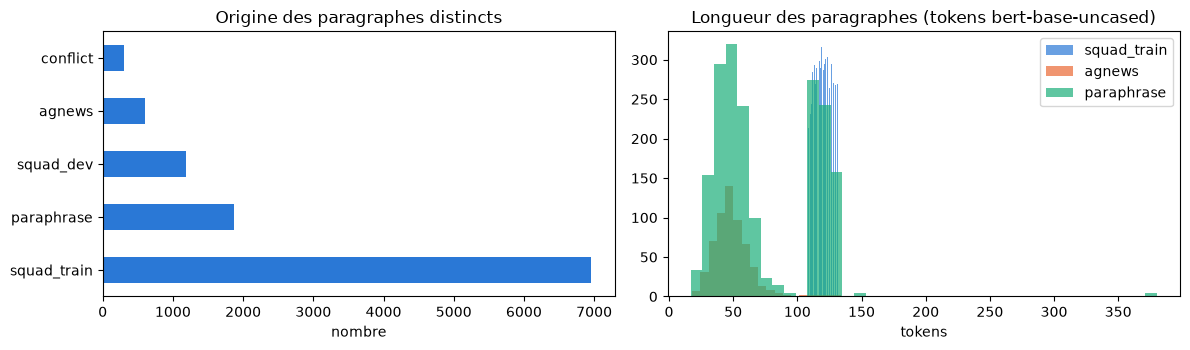

In [5]:
src = pd.Series([p.source for p in paras.values()]).value_counts()
toks = pd.DataFrame({"source": [p.source for p in paras.values()],
                     "tokens": [p.tokens for p in paras.values()]})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
src.plot.barh(ax=ax[0], color="#2a78d6")
ax[0].set_title("Origine des paragraphes distincts"); ax[0].set_xlabel("nombre")
for s, c in [("squad_train", "#2a78d6"), ("agnews", "#eb6834"), ("paraphrase", "#1baf7a")]:
    ax[1].hist(toks[toks.source == s].tokens, bins=40, alpha=.7, label=s, color=c)
ax[1].set_title("Longueur des paragraphes (tokens bert-base-uncased)")
ax[1].set_xlabel("tokens"); ax[1].legend()
plt.tight_layout(); plt.show()

Le remplissage et les paraphrases sont bien concentrés dans la fenêtre 108–132 tokens, alors que les articles AG News gardent leur longueur naturelle (médiane d'environ 47 tokens) : **le signal n'est jamais modifié**.

### 3.3 Un exemple concret : la contradiction

En recherche et en QA, le paragraphe contradictoire est une copie du paragraphe gold dans laquelle chaque occurrence de l'entité réponse est remplacée par une autre entité **du même type spaCy**. Voici un échantillon réel (QA, axe contradiction, N = 1, conflit placé avant le signal) :

In [6]:
ex = next(s for s in samples if s["task"] == "qa" and s["axis"] == "contradiction"
          and s["N"] == 1 and s["contradiction_pos"] == "before")
print("Question               :", ex["question"])
print("Réponses acceptées     :", ex["answers"])
print("Entité de remplacement :", ex["conflict_value"])
for pid, txt in zip(ex["paragraphs"], ex["context"]):
    role = "CONTRADICTOIRE" if pid == ex["conflict_id"] else "SIGNAL"
    print(f"\n[{role}] {txt}")

Question               : When were the shortcomings of Aristotle's physics overcome?
Réponses acceptées     : ['17th century', 'the 17th century']
Entité de remplacement : between 2004 and 2014

[CONTRADICTOIRE] The shortcomings of Aristotelian physics would not be fully corrected until between 2004 and 2014 work of Galileo Galilei, who was influenced by the late Medieval idea that objects in forced motion carried an innate force of impetus. Galileo constructed an experiment in which stones and cannonballs were both rolled down an incline to disprove the Aristotelian theory of motion early in between 2004 and 2014. He showed that the bodies were accelerated by gravity to an extent that was independent of their mass and argued that objects retain their velocity unless acted on by a force, for example friction.

[SIGNAL] The shortcomings of Aristotelian physics would not be fully corrected until the 17th century work of Galileo Galilei, who was influenced by the late Medieval idea that o

Les deux paragraphes ne diffèrent que par l'entité réponse. On remarque aussi une limite de la méthode : le remplacement d'une date (*the 17th century*) par une autre date (*between 2004 and 2014*) donne parfois une phrase peu naturelle. Le manifeste de construction indique la répartition des types d'entités retenus :

In [7]:
pd.Series(manifest["build_info"]["squad_answer_types"]).sort_values(ascending=False).to_frame("effectif").T

,DATE,PERSON,ORG,CARDINAL,GPE,LOC,NORP,FAC,MONEY,LAW,PERCENT,QUANTITY,PRODUCT,LANGUAGE,EVENT,WORK_OF_ART,ORDINAL
effectif,70,61,46,31,21,21,14,9,5,4,4,4,3,2,2,2,1


### 3.4 Un exemple de paraphrase

Pour l'axe de redondance, le signal est répété cinq fois, en copies exactes ou en paraphrases obtenues par **rétro-traduction** anglais → français → anglais avec MarianMT. Nous traduisons phrase par phrase : traduit d'un seul bloc, le paragraphe perdait souvent sa dernière phrase, et la part de questions utilisables est passée de 46 % à 85 % grâce à cette correction.

In [8]:
ex = next(s for s in samples if s["task"] == "qa" and s["axis"] == "redundancy"
          and s["redundancy_mode"] == "paraphrase" and s["N"] == 1)
gold = paras[ex["signal_id"]].text
print("ORIGINAL   :", gold, "\n")
for pid in ex["paragraphs"][:2]:
    if pid != ex["signal_id"]:
        print("PARAPHRASE :", paras[pid].text, "\n")

ORIGINAL   : The shortcomings of Aristotelian physics would not be fully corrected until the 17th century work of Galileo Galilei, who was influenced by the late Medieval idea that objects in forced motion carried an innate force of impetus. Galileo constructed an experiment in which stones and cannonballs were both rolled down an incline to disprove the Aristotelian theory of motion early in the 17th century. He showed that the bodies were accelerated by gravity to an extent that was independent of their mass and argued that objects retain their velocity unless acted on by a force, for example friction. 

PARAPHRASE : The shortcomings of Aristotelian physics would not be completely corrected before the work of the 17th century of Galilee, which was influenced by the late medieval idea that objects in forced movement carried an innate force of impulse. Galileo built an experiment in which stones and cannon balls were both rolled down a slope to refute the Aristotelian theory of movemen

### 3.5 Garanties de validité

La construction vérifie automatiquement plusieurs invariants et s'interrompt en cas de violation : le signal est présent et identique octet par octet à la source ; nombre de paragraphes, tokens et profondeur correspondent à la condition ; en recherche et en QA, la réponse n'apparaît jamais dans le remplissage ; une copie modifiée ne contient plus la réponse mais contient l'entité de remplacement. Vérifions quelques-uns de ces invariants directement sur le jeu de données :

In [9]:
from ssb.paragraphs import contains_answer

bad_signal = sum(paras[s["signal_id"]].text not in s["context"] for s in samples)
bad_size = sum(len(s["context"]) != s["n_paragraphs"] for s in samples)
leak = 0
for s in samples:
    if s["task"] != "classification" and s["answers"]:
        evidence = set(s["signal_ids"]) | {s["conflict_id"]}
        leak += any(contains_answer(t, a) for pid, t in zip(s["paragraphs"], s["context"])
                    if pid not in evidence for a in s["answers"])
print("signal absent ou modifié :", bad_signal)
print("taille de contexte fausse :", bad_size)
print("réponse dans le remplissage :", leak)

signal absent ou modifié : 0
taille de contexte fausse : 0
réponse dans le remplissage : 0


## 4. Méthodologie

### 4.1 Les cinq axes de perturbation

Un seul facteur varie à la fois, à partir d'un contexte de base « signal + remplissage aléatoire ».

| Axe | Ce qui change | Niveaux |
|---|---|---|
| **Dilution** | seulement N (part du signal = 1/N) | N = 1, 5, 20, 100 |
| **Bruit sémantique** | le remplissage devient des *négatifs difficiles* : paragraphes les plus proches de la requête selon `all-mpnet-base-v2`, sans la réponse | aléatoire / difficile |
| **Redondance** | le signal apparaît k fois | k = 1 ou 5 ; copies ou paraphrases |
| **Contradiction** | un paragraphe contradictoire accolé au signal | avant / après |
| **Position** | profondeur relative du signal | d = 0 ; 0,5 ; 1 |

L'encodeur qui choisit les négatifs difficiles (mpnet) n'est **pas** un modèle évalué, pour ne favoriser aucun d'eux.

### 4.2 Tâches et modèles

| Tâche | Modèle | Type | Contexte long |
|---|---|---|---|
| A. Classification (AG News) | `tfidf-lr` | TF-IDF + régression logistique | aucune limite |
| | `bert-truncate` | BERT-base fine-tuné AG News | 512 premiers tokens |
| | `bert-chunk-mean` | même BERT | moyenne des logits sur des blocs de 512 tokens |
| B. Recherche de passage (SQuAD 2.0) | `tfidf` | lexical, cosinus | score par paragraphe |
| | `bm25` | lexical, BM25Okapi | score par paragraphe |
| | `minilm` | dense, `all-MiniLM-L6-v2` | score par paragraphe |
| C. QA extractive (SQuAD 2.0) | `distilbert-squad` | DistilBERT SQuAD 1.1 (pas d'abstention) | fenêtres glissantes 384/128 |
| | `roberta-squad2` | RoBERTa-base SQuAD 2.0 | fenêtres glissantes 384/128 |

`bert-truncate` et `bert-chunk-mean` partagent exactement les mêmes poids : la comparaison isole l'effet de la **stratégie de lecture**. Rappelons les deux fonctions de score lexicales :

$$w(t,d) = \mathrm{tf}(t,d)\cdot\log\frac{|D|}{\mathrm{df}(t)} \qquad
\mathrm{BM25}(q,d) = \sum_{t\in q}\mathrm{IDF}(t)\,\frac{f(t,d)\,(k_1+1)}{f(t,d)+k_1\left(1-b+b\,\frac{|d|}{\mathrm{avgdl}}\right)}$$

Aucune des deux ne dépend de l'ordre des mots : elles sont par construction insensibles à la position du signal.

### 4.3 Démonstration : les modèles de recherche, en direct

Les modèles lexicaux sont assez rapides pour être réexécutés ici sur les **9 900 échantillons** de la tâche de recherche, avec le code du projet (`ssb/tasks/retrieval.py`). Les statistiques TF-IDF et BM25 sont calculées sur tous les paragraphes du jeu, de sorte qu'un score ne dépend jamais des autres paragraphes présents dans le contexte. Les égalités parfaites, fréquentes entre le gold et sa copie contradictoire (l'entité remplacée figure rarement dans la question), sont départagées par une clé aléatoire fixée par la graine, jamais par la position.

In [10]:
import time
from ssb.tasks.retrieval import BM25Ranker, TfidfRanker

mc = {m.name: m for m in cfg.models}
corpus = {pid: p.text for pid, p in paras.items()}
ret = [s for s in samples if s["task"] == "retrieval"]

live, rankers = {}, {}
for name, cls in [("tfidf", TfidfRanker), ("bm25", BM25Ranker)]:
    t0 = time.time()
    ranker = rankers[name] = cls(mc[name], corpus)
    live[name] = ranker.predict(ret)
    print(f"{name:6s} : {len(ret):,} échantillons classés en {time.time() - t0:.1f} s")

# comparaison avec les prédictions de l'exécution complète sur GPU T4
for name in live:
    stored = {d["sample_id"]: d["rank"] for d in map(json.loads,
              Path(f"results/main/predictions/{name}.jsonl").read_text().splitlines())}
    same = np.mean([p["rank"] == stored[s["id"]] for p, s in zip(live[name], ret)])
    print(f"{name:6s} : rang identique à l'exécution Kaggle pour {100 * same:.1f} % des échantillons")

tfidf  : 9,900 échantillons classés en 5.6 s


bm25   : 9,900 échantillons classés en 4.1 s
tfidf  : rang identique à l'exécution Kaggle pour 100.0 % des échantillons
bm25   : rang identique à l'exécution Kaggle pour 100.0 % des échantillons


Les rangs recalculés sur processeur sont identiques à ceux de l'exécution complète : le pipeline est déterministe. Voyons ce que fait BM25 sur l'exemple de contradiction présenté plus haut, à N = 20 :

In [11]:
s = next(s for s in ret if s["axis"] == "contradiction" and s["N"] == 20
         and s["contradiction_pos"] == "before")
sc = rankers["bm25"].scores(s["question"], s["paragraphs"])
role = ["SIGNAL" if p in s["signal_ids"] else "CONTRADICTOIRE" if p == s["conflict_id"]
        else "remplissage" for p in s["paragraphs"]]
top = (pd.DataFrame({"paragraphe": s["paragraphs"], "rôle": role, "score BM25": sc})
         .sort_values("score BM25", ascending=False).head(5).reset_index(drop=True))
print("Question :", s["question"]); top

Question : When were the shortcomings of Aristotle's physics overcome?


,paragraphe,rôle,score BM25
0,sq:a06dc0073cba,SIGNAL,20.4
1,cf:a518aec75932,CONTRADICTOIRE,19.8
2,w:9ea953d67f57,remplissage,10.3
3,w:ae59017fccd4,remplissage,9.8
4,w:8cf3aa358c56,remplissage,9.7


Le signal et sa copie contradictoire partagent tous les mots de la question : ils obtiennent des scores très proches (ici 20,4 contre 19,8), loin devant le remplissage, et sur l'ensemble des échantillons de contradiction `bm25` leur donne **exactement le même score** dans 27,7 % des cas. Un modèle lexical n'a alors aucun moyen de savoir lequel croire.

### 4.4 Le décodage de la question-réponse

La version 5 de `transformers` a supprimé le pipeline de QA extractive ; nous avons donc réimplémenté le décodage (`ssb/tasks/qa.py`). Le contexte est découpé en fenêtres de 384 tokens qui se chevauchent (pas de 128). Dans chaque fenêtre, les logits de début et de fin sont normalisés par softmax sur les tokens du contexte et le token `[CLS]`, et le score d'une plage $(i, j)$ vaut

$$s(i,j) = p_{\text{début}}(i)\,p_{\text{fin}}(j), \qquad i \le j < i + 30,$$

tandis que le score d'abstention est $s_\varnothing = p_{\text{début}}(\texttt{CLS})\,p_{\text{fin}}(\texttt{CLS})$. `roberta-squad2` s'abstient quand le plus petit score d'abstention sur les fenêtres dépasse le meilleur score de plage. La fonction centrale, testée unitairement :

In [12]:
import inspect
from ssb.tasks.qa import best_span
print(inspect.getsource(best_span))

# petit exemple : 6 tokens, [CLS] en position 0, contexte en positions 2 à 5
start = np.array([0., -9, 1, 4, 0, 0]); end = np.array([0., -9, 0, 1, 5, 0])
mask = np.array([0, 0, 1, 1, 1, 1])
i, j, score, null = best_span(start, end, mask, cls_index=0)
print(f"meilleure plage : tokens {i} à {j}, score {score:.3f} ; score d'abstention {null:.3f}")

def best_span(start_logits: np.ndarray, end_logits: np.ndarray, context_mask: np.ndarray,
              cls_index: int, max_answer_len: int = MAX_ANSWER_LEN) -> tuple[int, int, float, float]:
    """Best (start, end, score) in one window, plus the window's null score.

    context_mask is 1 on context tokens. Probabilities are a softmax over context tokens
    and CLS, as in the transformers v4 question-answering pipeline."""
    keep = context_mask.astype(bool).copy()
    keep[cls_index] = True
    s = np.where(keep, start_logits, -10000.0)
    e = np.where(keep, end_logits, -10000.0)
    s = np.exp(s - s.max())
    s /= s.sum()
    e = np.exp(e - e.max())
    e /= e.sum()
    null = float(s[cls_index] * e[cls_index])
    s[cls_index] = e[cls_index] = 0.0
    outer = np.tril(np.triu(np.outer(s, e)), max_answer_len - 1)
    i, j = np.unravel_index(int(outer.argmax()), outer.shape)
    return int(i), int(j), float(outer[i, j]), null

meilleure plage : tokens 3 à 4, score 0.872 ; score d

### 4.5 Métriques

| Tâche | Score principal | Scores secondaires | Confiance |
|---|---|---|---|
| Classification | précision | macro-F1, score de Brier | probabilité softmax maximale |
| Recherche | Recall@1 (toute copie du gold compte) | Recall@5, MRR | — |
| QA | exact match (questions avec réponse), précision d'abstention (sans réponse) | F1 token | score de la plage |

La fiabilité est mesurée par la **surconfiance** (confiance moyenne − score) et l'**erreur de calibration attendue** sur 10 intervalles :

$$\mathrm{ECE} = \sum_{b=1}^{10}\frac{|B_b|}{n}\,\bigl|\mathrm{acc}(B_b)-\mathrm{conf}(B_b)\bigr|$$

Pour la contradiction, chaque prédiction est classée selon qu'elle suit le signal, le paragraphe contradictoire, aucun des deux, ou les place à égalité.

### 4.6 Incertitude et indicateurs de saturation

Avec 300 exemples par tâche, quelques points d'écart peuvent venir du hasard. Chaque valeur est donc accompagnée d'un **intervalle de confiance à 95 %** obtenu par 1 000 rééchantillonnages bootstrap **des exemples de base** : quand un exemple est tiré, toutes ses variantes le sont avec lui, et les comparaisons entre conditions sont appariées. Quand une hypothèse comporte plusieurs comparaisons, les valeurs p sont corrigées par la méthode de **Holm**.

Trois indicateurs résument chaque courbe score = f(N) :

- **N\*** (saturation) : plus petit N dont le gain sur le niveau précédent est inférieur à 1 point ;
- **N†** (dégradation) : plus petit N après le pic significativement inférieur au pic ;
- **SSS** (*Semantic Saturation Score*) : aire sous la courbe en fonction de $\log_{10} N$, normalisée par l'étendue logarithmique (1 = parfait partout, 0,25 = hasard en classification).

$$\mathrm{SSS} = \frac{1}{\log_{10}N_{\max}-\log_{10}N_{\min}}\int s(N)\,\mathrm{d}\log_{10}N$$

### 4.7 Hypothèses pré-enregistrées

Huit hypothèses ont été rédigées et versionnées (`HYPOTHESES.md`) **avant** toute évaluation sur v0.1, chacune avec un test et un critère de décision précis :

| | Hypothèse |
|---|---|
| H1 | Tous les modèles se dégradent quand N croît, et le bruit difficile fait plus de mal que le bruit aléatoire. |
| H2 | Les sacs de mots n'ont pas de biais de position ; `bert-truncate` s'effondre au-delà des 512 premiers tokens. |
| H3 | `chunk-mean` corrige le biais de position mais se dégrade toujours avec la dilution. |
| H4 | Les modèles lexicaux battent l'encodeur dense sur négatifs difficiles ; le dense gagne sur bruit aléatoire. |
| H5 | La redondance ralentit la dégradation ; les copies aident plus TF-IDF, les paraphrases plus les Transformers. |
| H6 | Face à une contradiction, les modèles de QA choisissent la réponse contradictoire environ une fois sur deux, et la position joue. |
| H7 | La confiance reste élevée pendant que la précision baisse. |
| H8 | Plus N croît, plus les questions sans réponse reçoivent de fausses réponses (`roberta-squad2`). |

### 4.8 Exécution complète

La construction du jeu (24 min) et l'évaluation des huit modèles (0,55 h) ont été exécutées sur un GPU NVIDIA T4 (Kaggle) avec `kaggle/run.py`. Les commandes correspondantes sont rappelées ci-dessous ; elles sont désactivées par défaut car elles nécessitent un GPU et téléchargent plusieurs modèles. Les prédictions obtenues sont versionnées dans `results/main/predictions/`, et la suite du notebook les analyse.

In [13]:
RUN_FULL_PIPELINE = False   # mettre True sur une machine avec GPU pour tout reconstruire

if RUN_FULL_PIPELINE:
    for step in ("build", "run", "report"):
        subprocess.run([sys.executable, "-m", "ssb.cli", step, "--config", "configs/main.yaml"],
                       check=True)
else:
    runtimes = json.loads(Path("results/main/run_manifest.json").read_text())["models"]
    display(pd.DataFrame(runtimes).T[["task", "model_id", "seconds"]]
              .rename(columns={"seconds": "temps T4 (s)"}))

,task,model_id,temps T4 (s)
tfidf-lr,classification,None,44.5
bert-truncate,classification,textattack/bert-base-uncased-ag-news,157.5
bert-chunk-mean,classification,textattack/bert-base-uncased-ag-news,698.9
tfidf,retrieval,None,10.8
bm25,retrieval,None,8.3
minilm,retrieval,sentence-transformers/all-MiniLM-L6-v2,3.6
distilbert-squad,qa,distilbert-base-cased-distilled-squad,339.3
roberta-squad2,qa,deepset/roberta-base-squad2,706.8


## 5. Résultats

On relit les prédictions de l'exécution complète, on les confronte aux réponses attendues, puis on calcule toutes les métriques avec leurs intervalles bootstrap (environ une minute).

In [14]:
from ssb.analysis import analyse, score_run

t0 = time.time()
scores = score_run(cfg)
res = analyse(cfg, scores)
M, LB = res["metrics"], res["leaderboard"]
print(f"{len(scores):,} prédictions analysées en {time.time() - t0:.0f} s")

ORDER = [m.name for m in cfg.models]
TASK = {m.name: {"classification": "Classification", "retrieval": "Recherche", "qa": "QA"}[m.task]
        for m in cfg.models}

def table(curve, ns=(1, 5, 20, 100), metric="score", ci=False):
    d = M[(M.curve == curve) & (M.metric == metric) & (M.N.isin(ns))].copy()
    if ci:
        d["v"] = d.apply(lambda r: f"{100*r.value:.1f} [{100*r.ci_low:.1f} ; {100*r.ci_high:.1f}]", axis=1)
    else:
        d["v"] = (100 * d.value).round(1)
    t = d.pivot(index="model", columns="N", values="v").reindex(ORDER).dropna(how="all")
    t.insert(0, "tâche", [TASK[m] for m in t.index])
    return t

def fig(name, width=1000):
    display(Image(filename=f"figures/fr/{name}.png", width=width))

70,500 prédictions analysées en 4 s


### 5.1 Dilution : plus de contexte n'aide aucun modèle

Score principal (en %) selon le nombre de paragraphes, avec remplissage aléatoire :

In [15]:
t = table("dilution")
t["baisse 1→100"] = (t[1] - t[100]).round(1)
t.sort_values("baisse 1→100", ascending=False)

N,tâche,1,5,20,100,baisse 1→100
model,,,,,,
bert-truncate,Classification,97.7,34.7,27.7,24.0,73.7
bert-chunk-mean,Classification,97.7,37.7,25.3,25.0,72.7
tfidf-lr,Classification,95.7,42.7,29.7,27.7,68.0
distilbert-squad,QA,89.3,82.7,85.3,77.3,12.0
bm25,Recherche,100.0,98.7,97.0,93.7,6.3
minilm,Recherche,100.0,100.0,97.3,94.3,5.7
tfidf,Recherche,100.0,99.0,97.0,94.7,5.3
roberta-squad2,QA,84.7,79.3,78.0,80.7,4.0


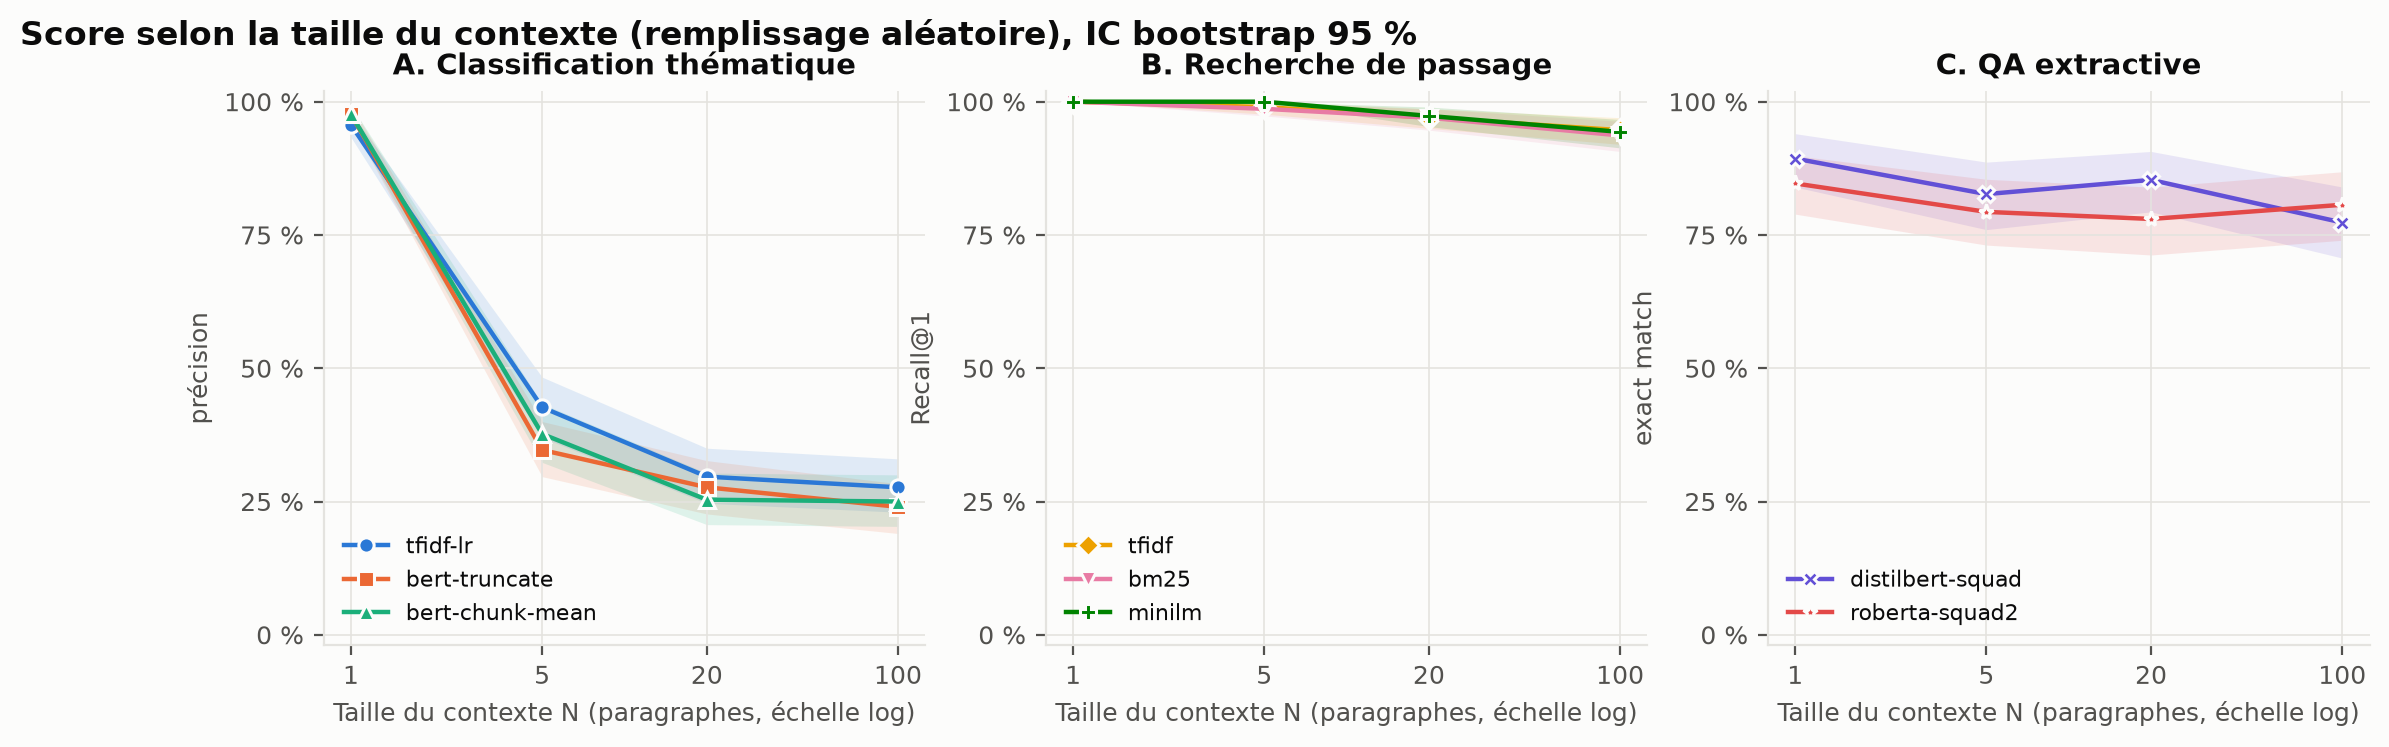

In [16]:
fig("fig1_main")

Les **huit modèles** se dégradent significativement entre N = 1 et N = 100. La classification s'effondre au niveau du hasard (25 % pour quatre classes) dès vingt paragraphes, alors que la recherche (−5 à −6 points) et la QA (−4 à −12 points) résistent beaucoup mieux. Le point de saturation N\* vaut 5 pour tous les modèles : au-delà de cinq paragraphes, ajouter du contexte n'apporte jamais de gain.

L'effondrement des classifieurs n'est pas du bruit : regardons la distribution des classes prédites à N = 100.

In [17]:
LABELS = ["World", "Sports", "Business", "Sci/Tech"]
c = scores[(scores.task == "classification") & (scores.axis == "dilution")]
pred = (c.assign(classe=c.pred.map(dict(enumerate(LABELS))))
         .pivot_table(index=["model", "N"], columns="classe", values="sample_id",
                      aggfunc="count", fill_value=0)[LABELS])
pred.loc[(slice(None), [1, 100]), :]

classe               World  Sports  Business  Sci/Tech
model           N                                     
bert-chunk-mean 1       75      75        75        75
                100      0       0         0       300
bert-truncate   1       75      75        75        75
                100      7      15         2       276
tfidf-lr        1       70      78        74        78
                100    118       0         0       182

À N = 1, les prédictions sont réparties sur les quatre classes ; à N = 100, `bert-chunk-mean` prédit **Sci/Tech pour les 300 articles**, `bert-truncate` pour 276 et `tfidf-lr` pour 182 (et *World* pour les autres). Le texte encyclopédique de Wikipedia « ressemble » à de la science et technologie pour ces modèles, et il submerge un article d'environ 48 tokens.

### 5.2 Bruit sémantique : un effet opposé selon la tâche

In [18]:
t = table("noise", ns=(5, 20, 100))
t["aléatoire N=100"] = table("dilution")[100]
t["écart (aléatoire − difficile)"] = (t["aléatoire N=100"] - t[100]).round(1)
t

N,tâche,5,20,100,aléatoire N=100,écart (aléatoire − difficile)
model,,,,,,
tfidf-lr,Classification,90.0,88.7,84.0,27.7,-56.3
bert-truncate,Classification,70.0,56.3,44.7,24.0,-20.7
bert-chunk-mean,Classification,78.7,54.0,45.7,25.0,-20.7
tfidf,Recherche,85.7,81.0,77.7,94.7,17.0
bm25,Recherche,87.7,83.3,79.3,93.7,14.4
minilm,Recherche,67.3,65.7,65.7,94.3,28.6
distilbert-squad,QA,73.3,65.3,49.3,77.3,28.0
roberta-squad2,QA,78.0,77.3,72.7,80.7,8.0


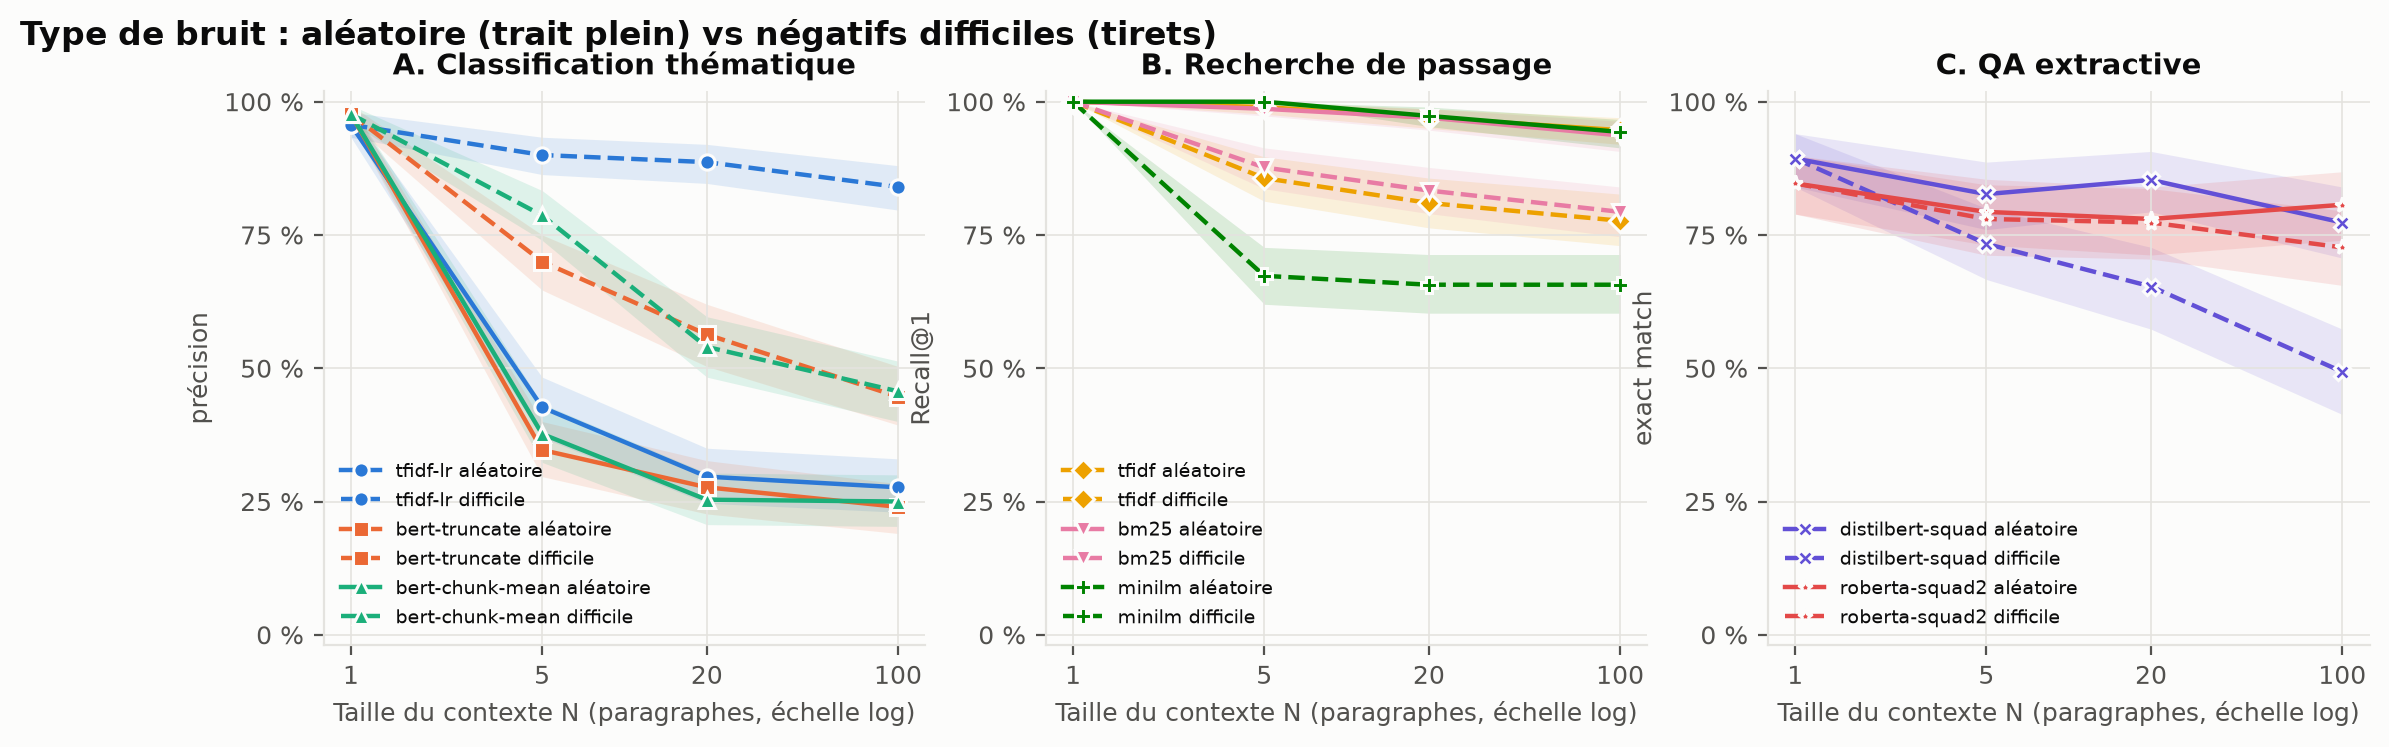

In [19]:
fig("fig2_noise_types")

En recherche et en QA, les négatifs difficiles font nettement plus de mal que le hasard (5 modèles sur 8). L'encodeur dense `minilm`, pourtant censé mieux saisir le sens, est le plus touché : 65,7 % de Recall@1, soit −28,7 points par rapport au bruit aléatoire, contre 78–79 % pour les modèles lexicaux. En classification, c'est l'inverse : `tfidf-lr` garde 84 % avec des paragraphes proches du thème, contre 27,7 % avec du hasard, car des paragraphes du même thème **renforcent** l'étiquette au lieu de la diluer.

### 5.3 Position du signal

In [20]:
pos = {}
for curve, d in [("position_d0", "d = 0"), ("position", "d = 0,5"), ("position_d1", "d = 1")]:
    pos[d] = table(curve, ns=(100,))[100]
pos = pd.DataFrame(pos)
pos.insert(0, "tâche", [TASK[m] for m in pos.index])
pos["écart max"] = (pos[["d = 0", "d = 0,5", "d = 1"]].max(axis=1)
                    - pos[["d = 0", "d = 0,5", "d = 1"]].min(axis=1)).round(1)
pos

,tâche,d = 0,"d = 0,5",d = 1,écart max
model,,,,,
tfidf-lr,Classification,27.7,27.7,27.7,0.000
bert-truncate,Classification,53.7,23.3,23.3,30.4
bert-chunk-mean,Classification,25.0,25.0,25.0,0.000
tfidf,Recherche,94.7,94.7,94.7,0.000
bm25,Recherche,93.7,93.7,93.7,0.000
minilm,Recherche,94.3,94.3,94.3,0.000
distilbert-squad,QA,78.7,79.3,79.3,0.600
roberta-squad2,QA,82.0,80.7,83.3,2.6


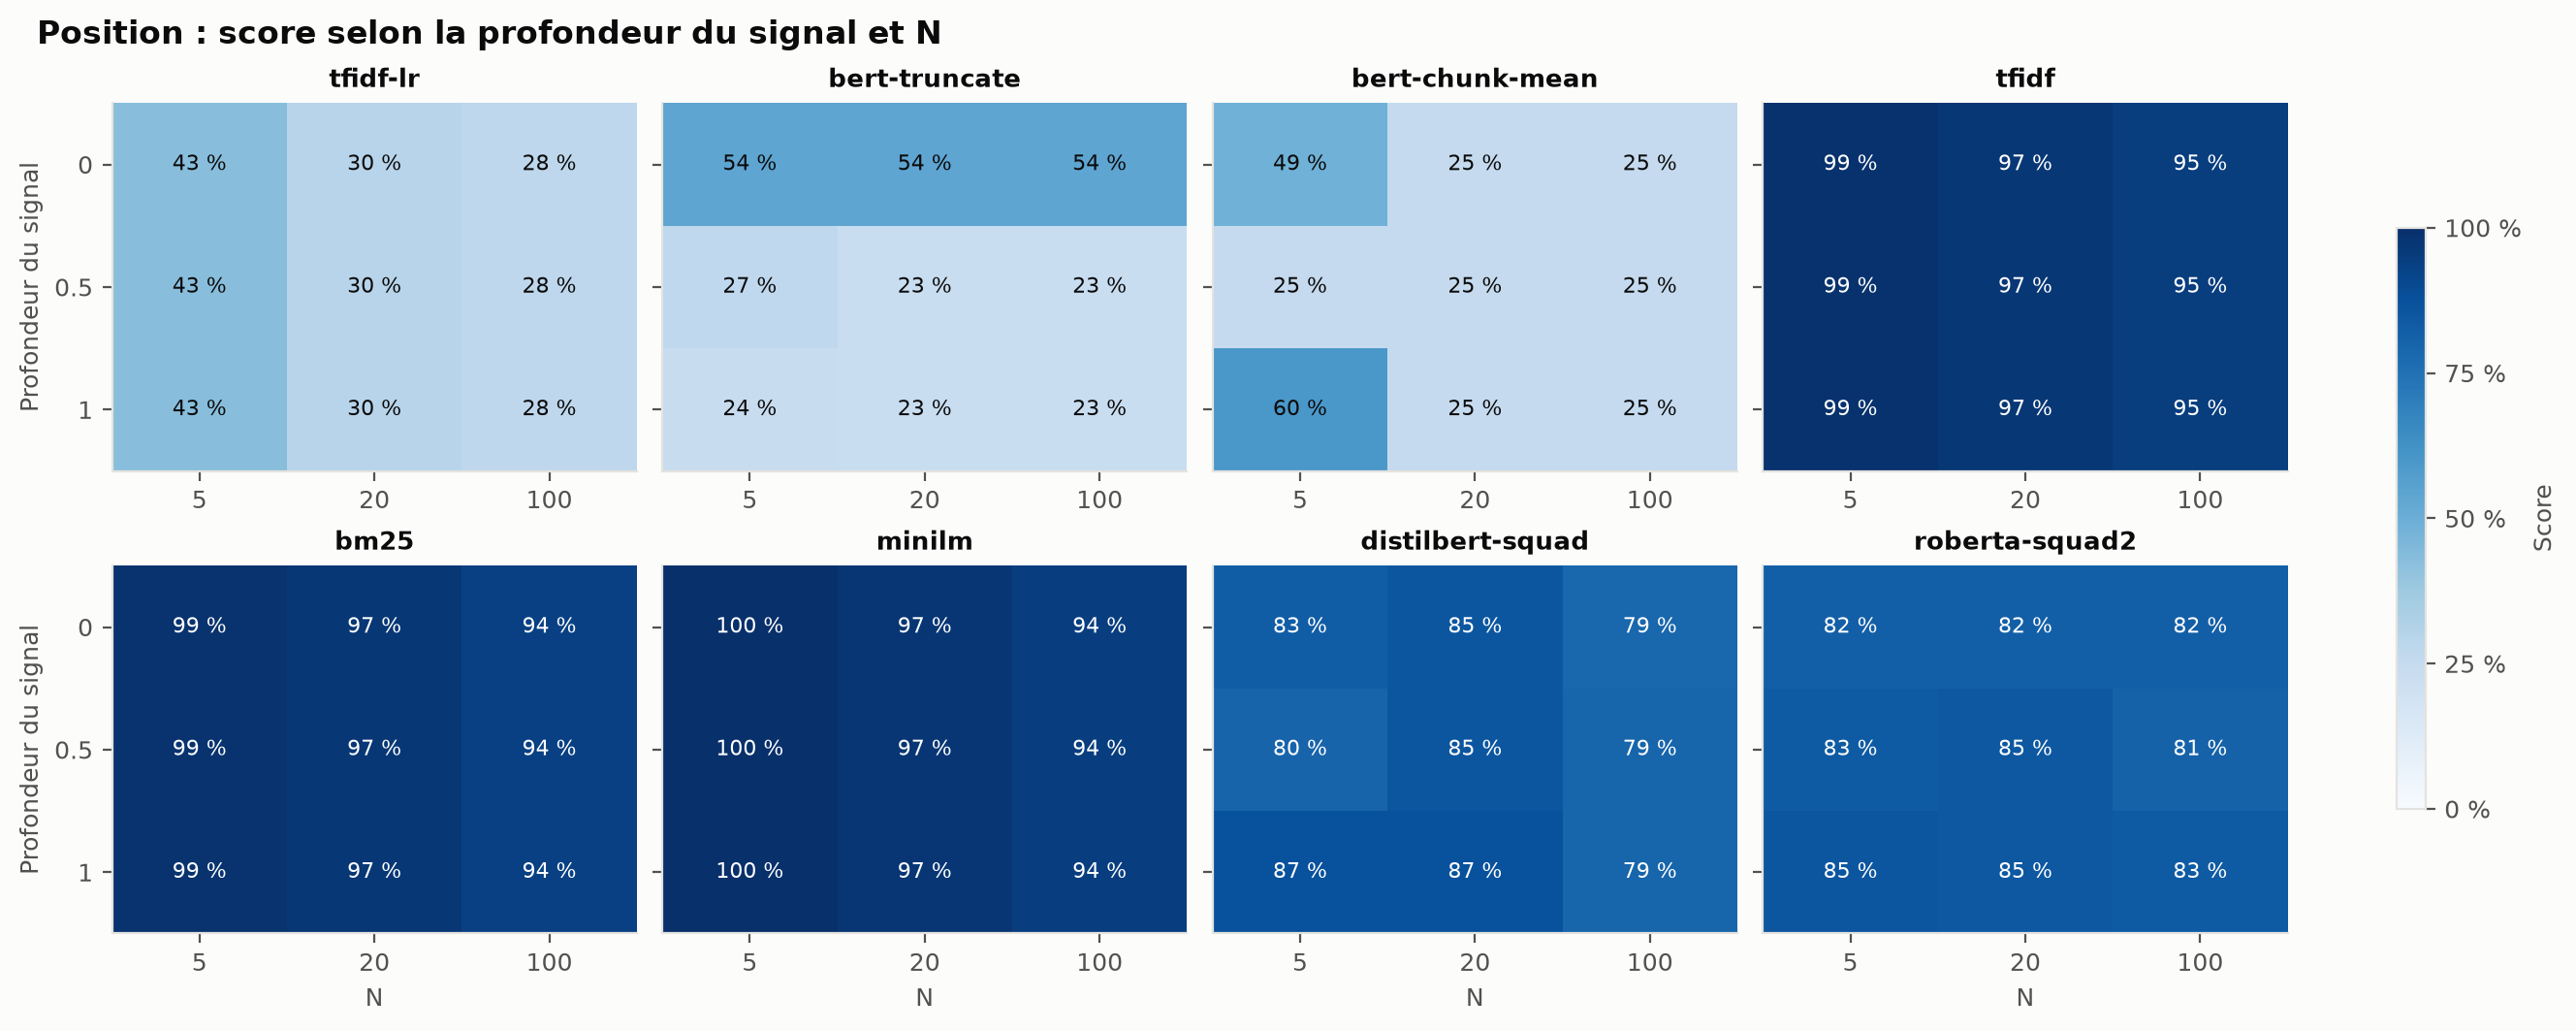

In [21]:
fig("fig3_position_heatmap")

Les sacs de mots (`tfidf-lr`, `tfidf`, `bm25`) ont exactement le même score à toutes les profondeurs. `bert-truncate` atteint 53,7 % quand le signal est en tête, mais 23,3 % au milieu ou à la fin, positions coupées par la troncature à 512 tokens. `bert-chunk-mean` supprime ce biais, mais reste au niveau du hasard à cause de la dilution. En QA, la fenêtre glissante rend la position presque neutre.

### 5.4 Contradiction

In [22]:
rows = []
for m in ["tfidf", "bm25", "minilm", "distilbert-squad", "roberta-squad2"]:
    r = {"modèle": m, "tâche": TASK[m]}
    for oc, lab in [("outcome_true", "vraie réponse"), ("outcome_conflicting", "contradictoire"),
                    ("outcome_tie", "égalité"), ("outcome_other", "autre")]:
        v = M[(M.model == m) & (M.metric == oc) & (M.N == 100) & M.curve.isin(["before", "after"])]
        r[lab] = round(100 * v.value.mean(), 1)
    for pos_ in ("before", "after"):
        v = M[(M.model == m) & (M.metric == "conflict_share") & (M.curve == pos_)]
        r[f"part de conflit ({'avant' if pos_ == 'before' else 'après'})"] = round(100 * v.value.iloc[0], 1)
    rows.append(r)
pd.DataFrame(rows).set_index("modèle")

,tâche,vraie réponse,contradictoire,égalité,autre,part de conflit (avant),part de conflit (après)
modèle,,,,,,,
tfidf,Recherche,66.3,33.0,0.700,0.000,33.2,33.2
bm25,Recherche,45.3,27.0,27.7,0.000,37.3,37.3
minilm,Recherche,60.7,39.3,0.000,0.000,39.3,39.3
distilbert-squad,QA,51.7,24.7,0.000,23.7,43.3,23.7
roberta-squad2,QA,54.7,24.3,0.000,21.0,36.3,25.6


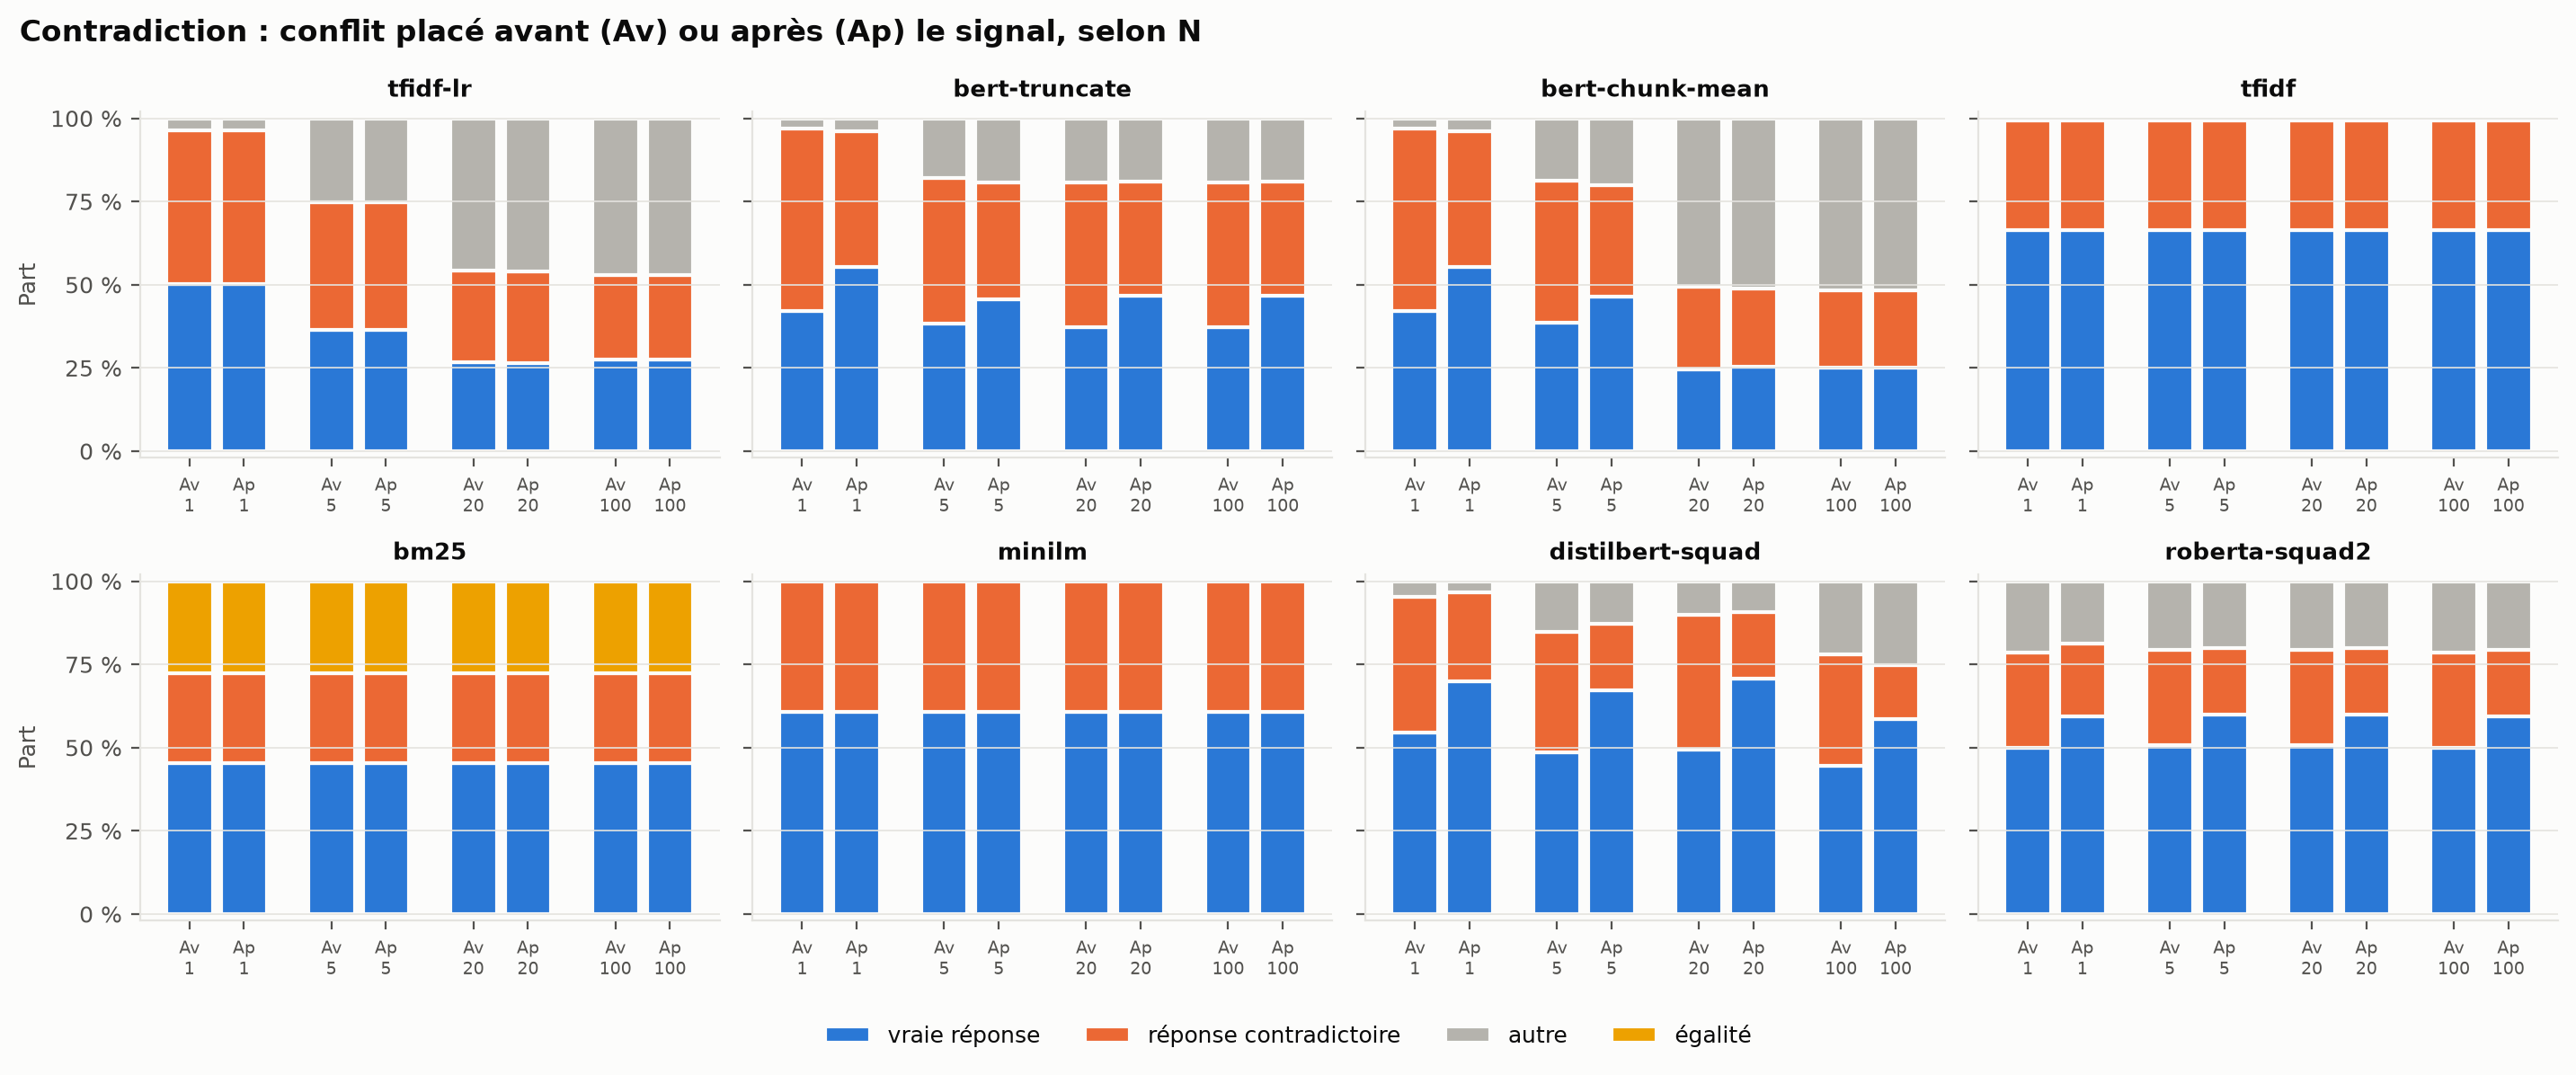

In [23]:
fig("fig5_contradiction")

Un paragraphe presque identique au signal trompe souvent les modèles. En recherche, la copie modifiée est classée première dans 27 à 39 % des cas, et `bm25` produit en plus 27,7 % d'égalités parfaites. En QA, parmi les réponses qui donnent l'une des deux entités, `distilbert-squad` choisit l'entité contradictoire dans 33,5 % des cas et `roberta-squad2` dans 30,9 %. **La position compte** : quand le conflit est placé avant le signal, `distilbert-squad` le choisit 19,6 points plus souvent (p < 0,001) et `roberta-squad2` 10,7 points plus souvent (p = 0,048). Le premier paragraphe lu l'emporte.

### 5.5 Calibration : la confiance ne suit pas la précision

In [24]:
rows = []
for m in ["tfidf-lr", "bert-truncate", "bert-chunk-mean", "distilbert-squad", "roberta-squad2"]:
    g = lambda met, n: M[(M.model == m) & (M.curve == "dilution") & (M.metric == met) & (M.N == n)].value.iloc[0]
    rows.append({"modèle": m, "confiance N=1": 100 * g("confidence", 1), "score N=1": 100 * g("score", 1),
                 "confiance N=100": 100 * g("confidence", 100), "score N=100": 100 * g("score", 100),
                 "ECE N=1": g("ece", 1), "ECE N=100": g("ece", 100)})
pd.DataFrame(rows).set_index("modèle").round(3)

,confiance N=1,score N=1,confiance N=100,score N=100,ECE N=1,ECE N=100
modèle,,,,,,
tfidf-lr,90.6,95.7,75.6,27.7,0.051,0.479
bert-truncate,98.7,97.7,97.4,24.0,0.010,0.734
bert-chunk-mean,98.7,97.7,99.3,25.0,0.010,0.743
distilbert-squad,78.1,89.3,79.6,77.3,0.129,0.147
roberta-squad2,70.1,84.7,68.0,80.7,0.146,0.155


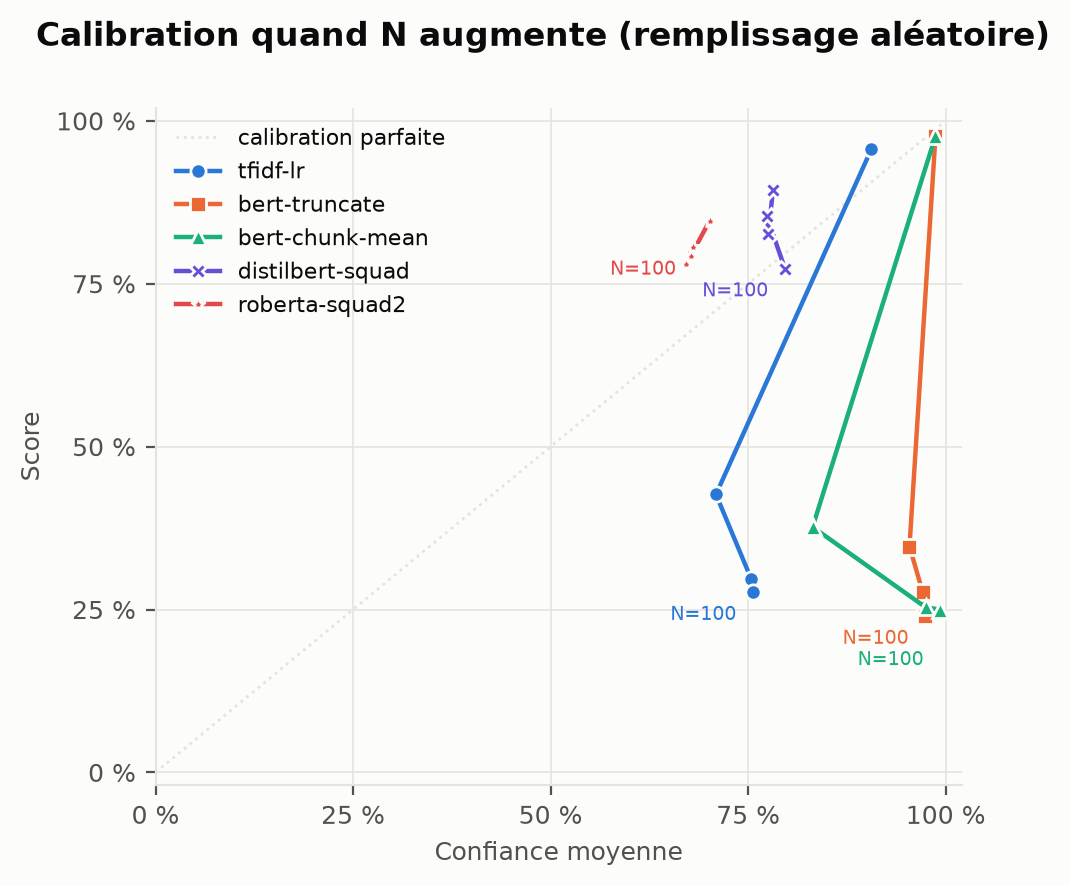

In [25]:
fig("fig6_calibration", width=560)

Les classifieurs se trompent en restant sûrs d'eux : `bert-chunk-mean` garde une confiance moyenne de 99 % avec 25 % de précision, et son ECE passe de 0,010 à 0,743. Rien dans sa sortie ne permet de détecter l'effondrement. `distilbert-squad` devient modérément surconfiant (+13,5 points), mais `roberta-squad2`, entraîné à s'abstenir, reste bien calibré (+1,9 point, non significatif). Sur les questions sans réponse, il s'abstient correctement dans environ 82 % des cas quel que soit N, mais perd 6,7 points sous bruit difficile.

### 5.6 Redondance

In [26]:
red = pd.DataFrame({"k = 1": table("dilution", ns=(100,))[100],
                    "k = 5 copies": table("redundancy_copy", ns=(100,))[100],
                    "k = 5 paraphrases": table("redundancy_paraphrase", ns=(100,))[100]})
sss = LB.pivot(index="model", columns="axis", values="SSS")
red["SSS k=1"] = sss["dilution"]; red["SSS copies"] = sss["redundancy_copy"]
red["SSS paraphrases"] = sss["redundancy_paraphrase"]
red.reindex(ORDER).round(3)

,k = 1,k = 5 copies,k = 5 paraphrases,SSS k=1,SSS copies,SSS paraphrases
model,,,,,,
tfidf-lr,27.7,35.3,35.0,0.451,0.681,0.679
bert-truncate,24.0,27.0,24.7,0.415,0.644,0.634
bert-chunk-mean,25.0,25.0,25.0,0.419,0.628,0.630
tfidf,94.7,94.7,95.3,0.978,0.983,0.984
bm25,93.7,93.7,94.0,0.975,0.981,0.982
minilm,94.3,94.3,95.3,0.981,0.984,0.985
distilbert-squad,77.3,75.3,80.7,0.838,0.857,0.833
roberta-squad2,80.7,86.0,83.3,0.801,0.809,0.786


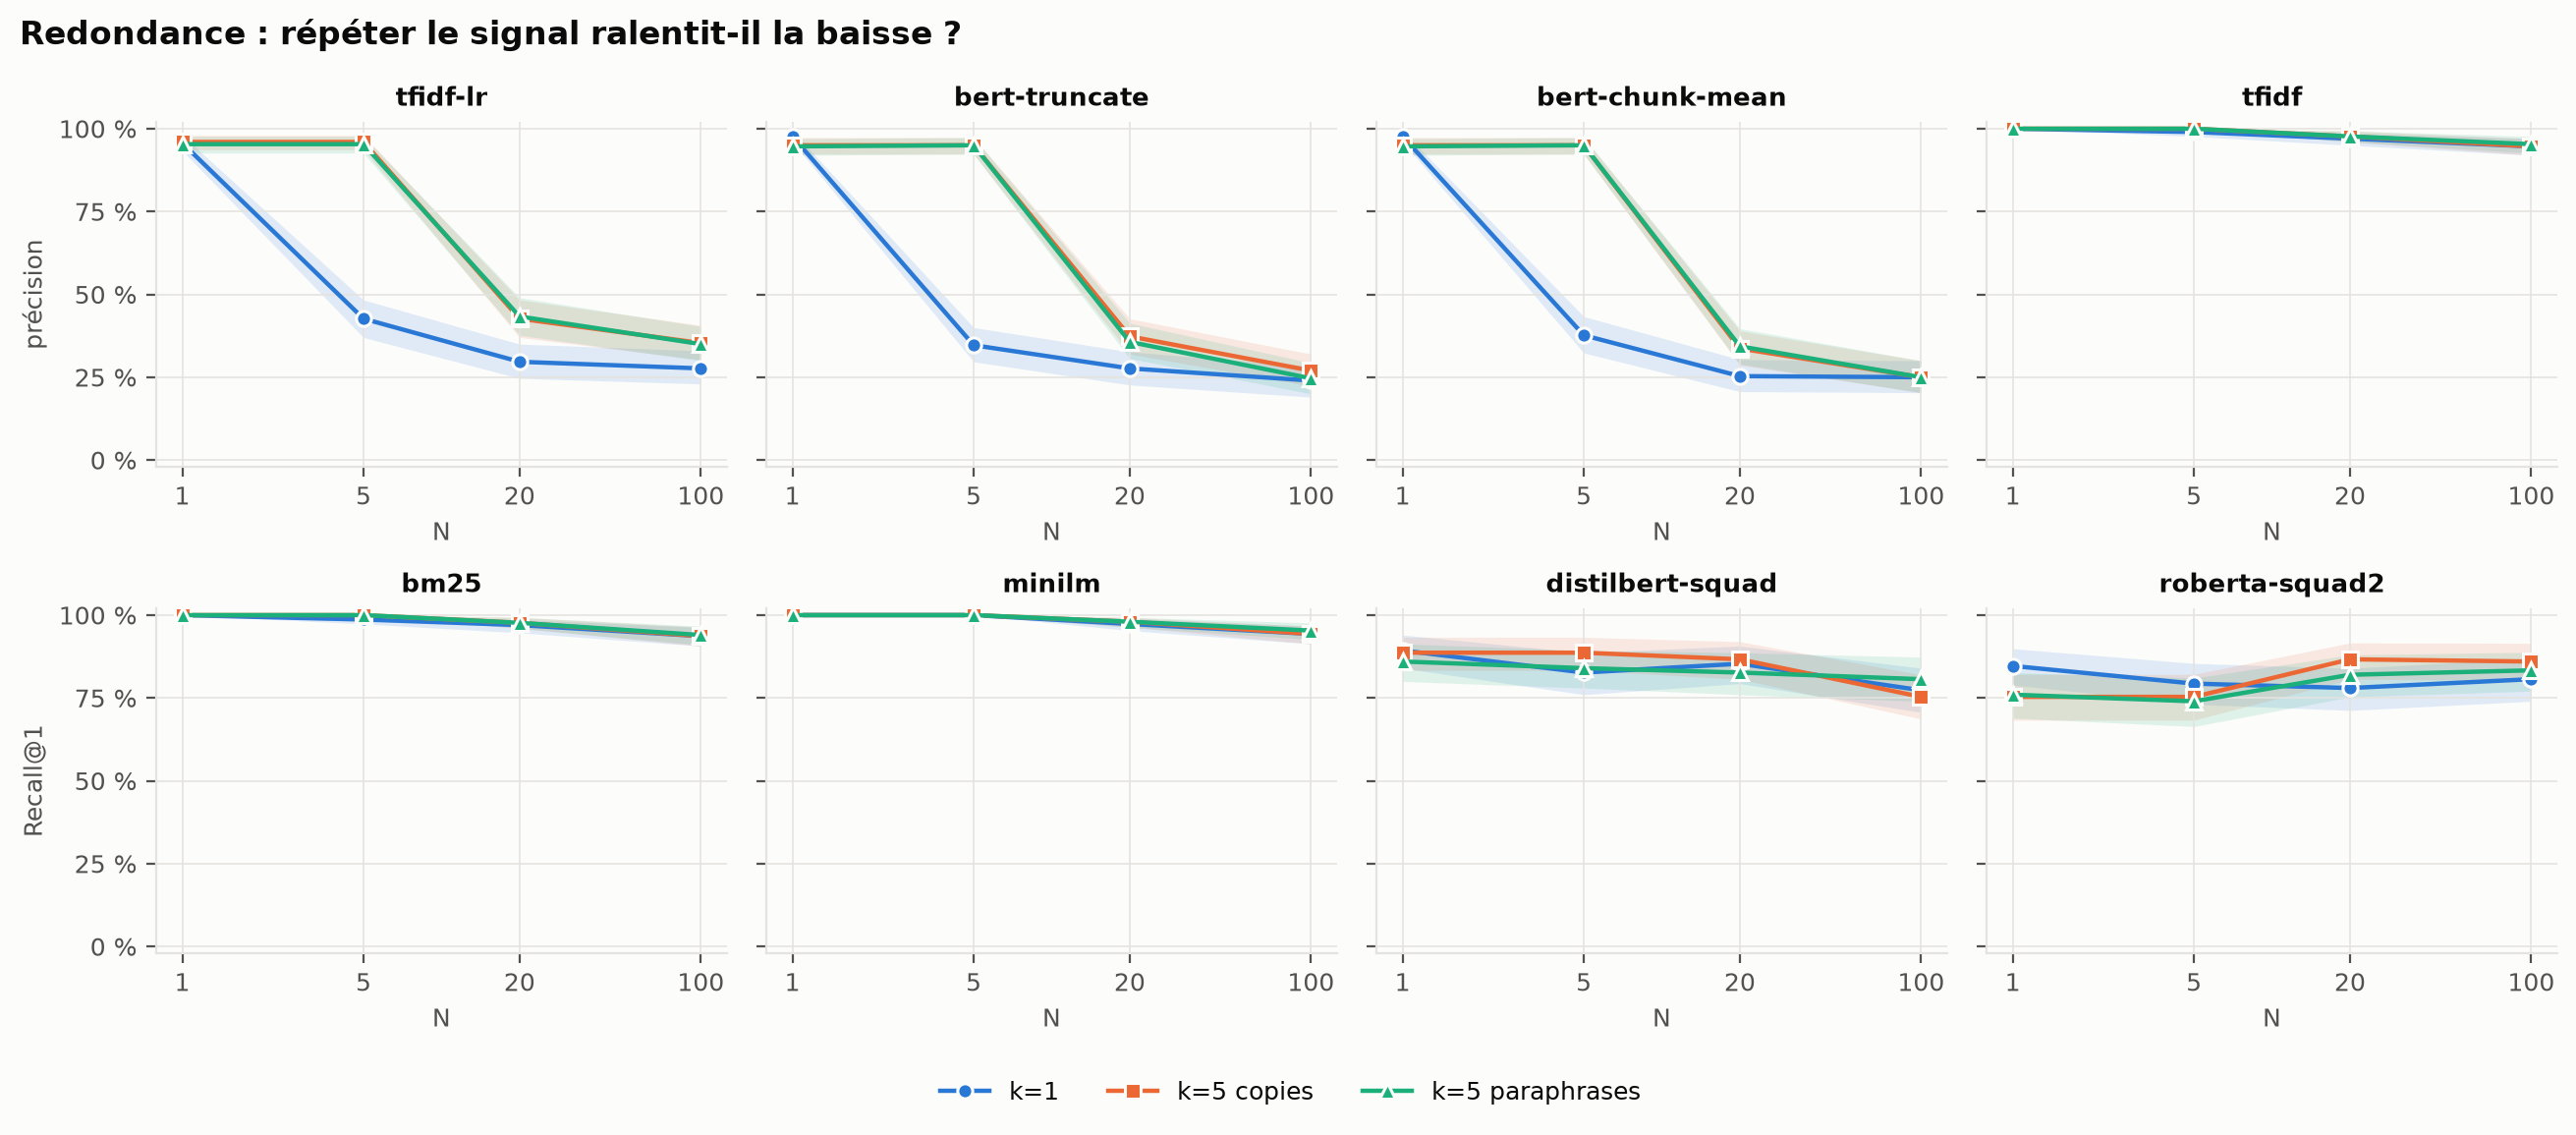

In [27]:
fig("fig4_redundancy")

Répéter le signal cinq fois atténue significativement la baisse pour 4 modèles sur 8 ; pour `tfidf-lr`, le SSS passe de 0,451 à 0,681. Mais dès que le remplissage dépasse largement les copies (N = 20 puis 100), la classification retombe : la redondance **retarde** la saturation sans l'empêcher. Copies et paraphrases donnent presque le même résultat (écarts de 0 à 5 points, rarement significatifs) : la rétro-traduction diversifie trop peu le lexique.

### 5.7 Classement global (SSS par axe)

In [28]:
AX = {"dilution": "Dilution", "noise": "Bruit", "redundancy_copy": "Copies",
      "redundancy_paraphrase": "Paraphrases", "contradiction": "Contradiction", "position": "Position"}
board = sss[list(AX)].rename(columns=AX)
board.insert(0, "tâche", [TASK[m] for m in board.index])
board.sort_values("Dilution", ascending=False).style.format(precision=3).background_gradient(
    cmap="Blues", subset=list(AX.values()), vmin=0.2, vmax=1)

axis,tâche,Dilution,Bruit,Copies,Paraphrases,Contradiction,Position
model,,,,,,,
minilm,Recherche,0.981,0.722,0.984,0.985,0.594,0.971
tfidf,Recherche,0.978,0.853,0.983,0.984,0.657,0.968
bm25,Recherche,0.975,0.870,0.981,0.982,0.582,0.965
distilbert-squad,QA,0.838,0.693,0.857,0.833,0.543,0.825
roberta-squad2,QA,0.801,0.780,0.809,0.786,0.520,0.833
tfidf-lr,Classification,0.451,0.895,0.681,0.679,0.341,0.321
bert-chunk-mean,Classification,0.419,0.682,0.628,0.630,0.348,0.251
bert-truncate,Classification,0.415,0.660,0.644,0.634,0.432,0.241


Les modèles de recherche dominent (SSS ≈ 0,98 sous dilution), suivis de la QA (0,80–0,84) puis des classifieurs (0,42–0,45). La contradiction est l'axe le plus difficile pour toutes les tâches.

### 5.8 Verdicts des hypothèses pré-enregistrées

Les verdicts sont calculés automatiquement par `ssb/analysis.py`, selon les tests fixés à l'avance :

In [29]:
FR = {"supported": "supportée", "partly supported": "partiellement supportée",
      "not supported": "non supportée"}
hyp = pd.DataFrame(res["hypotheses"])
hyp["verdict"] = hyp.verdict.apply(lambda v: next((FR[k] + v[len(k):] for k in sorted(FR, key=len, reverse=True)
                                                    if v.startswith(k)), v))
hyp[["id", "verdict"]].set_index("id")

,verdict
id,
H1,partiellement supportée
H2,supportée
H3,supportée
H4,partiellement supportée
H5,non supportée
H6,partiellement supportée (distilbert-squad)
H6,partiellement supportée (roberta-squad2)
H7,partiellement supportée
H8,partiellement supportée


| | Verdict | Élément déterminant |
|---|---|---|
| H1 | partiellement supportée | les 8 modèles se dégradent ; le bruit difficile est pire pour 5 sur 8 mais **aide** les classifieurs |
| H2 | **supportée** | écart de position nul pour les sacs de mots ; `bert-truncate` 23,3 % en milieu/fin contre 53,7 % en tête |
| H3 | **supportée** | `chunk-mean` : aucun écart de position, mais −72,7 points de dilution |
| H4 | partiellement supportée | `bm25` et `tfidf` battent `minilm` sur négatifs difficiles (+13,7 et +12,0 points) ; pas de différence sur bruit aléatoire |
| H5 | non supportée | la redondance aide 4 modèles sur 8, mais copies et paraphrases ne se distinguent pas |
| H6 | partiellement supportée | part de conflit 31–34 %, sous la fourchette prévue 35–65 % ; effet de position significatif |
| H7 | partiellement supportée | surconfiance +53 à +73 points (classifieurs), +13,5 (`distilbert`), pas pour `roberta-squad2` |
| H8 | partiellement supportée | abstention stable sous dilution, −6,7 points sous bruit difficile |

## 6. Discussion

**L'agrégation explique l'essentiel.** Le fil conducteur des résultats est la manière dont chaque modèle agrège le texte. Les modèles qui résument tout le contexte en une seule représentation (`tfidf-lr`, `bert-chunk-mean`) ou qui n'en lisent qu'un préfixe (`bert-truncate`) s'effondrent sous la dilution. Ceux qui examinent chaque passage séparément (les trois modèles de recherche, la QA à fenêtres glissantes) résistent. Cette distinction pèse bien plus que la sophistication du modèle : un BERT de 110 millions de paramètres fait moins bien qu'un simple TF-IDF qui score chaque paragraphe.

**Un contexte hors sujet ne dilue pas seulement le signal, il le remplace.** Les classifieurs ne répondent pas au hasard : ils prédisent la classe qui correspond le mieux au remplissage (*Sci/Tech* pour Wikipedia). Ils répondent correctement à la question « de quoi parle ce texte dans son ensemble ? », qui n'est pas la question posée.

**La confiance n'est pas un signal d'alarme.** Rejeter les prédictions peu confiantes, stratégie courante en production, serait ici inefficace : les classifieurs effondrés restent sûrs d'eux à plus de 97 %. Seul `roberta-squad2`, entraîné à reconnaître l'absence de réponse, reste calibré.

**Deux résultats contre-intuitifs.** Des paragraphes proches du thème aident la classification au lieu de la gêner, puisqu'ils partagent l'étiquette du signal. Et l'encodeur dense `minilm` est le plus trompé par les négatifs difficiles : ceux-ci ont été choisis pour leur proximité sémantique par un encodeur de la même famille, alors que les modèles lexicaux s'appuient sur les mots exacts de la question.

**La primauté du premier paragraphe.** Face à deux affirmations incompatibles, les modèles de QA favorisent celle qui apparaît en premier (jusqu'à 20 points d'écart). Dans un système qui concatène plusieurs documents, l'ordre choisi par le moteur de recherche influence donc la réponse finale.

**Limites.** Avec 300 exemples par tâche, les intervalles de confiance font environ ±5,5 points autour de 50 % : des effets plus faibles peuvent passer inaperçus. Le benchmark est limité à l'anglais ; les négatifs difficiles dépendent de l'encodeur mpnet ; le remplissage vient de Wikipedia, et un autre corpus attirerait sans doute les classifieurs vers une autre classe. Comme le signal est fixe et N = 1 le contexte le plus propre, la plupart des courbes ne peuvent que baisser : seule la redondance teste un gain possible. Enfin, le remplacement d'entités produit parfois des phrases peu naturelles (exemple de la section 3.3), ce qui rend la contradiction plus facile à repérer pour un humain qu'elle ne l'est pour les modèles.

## 7. Conclusion et perspectives

Ce projet a construit un benchmark contrôlé de **25 950 échantillons** pour mesurer la saturation sémantique de huit modèles NLP classiques sur trois tâches, en faisant varier séparément la quantité, la pertinence, la redondance, la cohérence et la position du contexte. La réponse à la question de départ est nette : **pour ces modèles, plus de contexte n'aide jamais au-delà de cinq paragraphes, et il nuit souvent.** La gravité de la dégradation dépend surtout de la manière dont le modèle agrège le texte, et la confiance des modèles ne permet pas de détecter leurs erreurs. Sur les huit hypothèses pré-enregistrées, deux sont supportées, cinq partiellement et une rejetée.

Plusieurs prolongements sont possibles : étendre le benchmark au français et à l'arabe ; utiliser d'autres corpus de remplissage pour vérifier si le biais vers une classe dépend de la source ; augmenter le nombre d'exemples pour détecter des effets plus fins ; produire des paraphrases plus diverses pour tester à nouveau H5 ; et appliquer le même protocole à des modèles de langage génératifs à longue fenêtre de contexte.

### Références

- Jia, R. et Liang, P. (2017). *Adversarial Examples for Evaluating Reading Comprehension Systems*. EMNLP.
- Liu, N. F. et al. (2024). *Lost in the Middle: How Language Models Use Long Contexts*. TACL.
- Rajpurkar, P., Jia, R. et Liang, P. (2018). *Know What You Don't Know: Unanswerable Questions for SQuAD*. ACL.
- Robertson, S. et Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond*.
- Shi, F. et al. (2023). *Large Language Models Can Be Easily Distracted by Irrelevant Context*. ICML.
- Thakur, N. et al. (2021). *BEIR: A Heterogeneous Benchmark for Zero-shot Evaluation of Information Retrieval Models*. NeurIPS.
- Zhang, X., Zhao, J. et LeCun, Y. (2015). *Character-level Convolutional Networks for Text Classification*. NeurIPS.
- Devlin, J. et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.